In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Age": [22, 25, 30, 35, 40, 45, 50, 55, 28, 38,
            32, 48, 52, 26, 42],
    "Income": [20000, 25000, 30000, 40000, 50000,
               60000, 70000, 80000, 28000, 45000,
               35000, 65000, 75000, 22000, 55000],
    "Experience": [1, 2, 5, 8, 10, 15, 20, 25, 4, 9,
                   6, 17, 22, 3, 12],
    "Credit_Score": [500, 520, 550, 600, 650,
                     700, 750, 800, 530, 620,
                     580, 720, 780, 510, 680],
    "Loan_Approved": [0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
                     0, 1, 1, 0, 1]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)


Original Dataset:


,Age,Income,Experience,Credit_Score,Loan_Approved
0,22,20000,1,500,0
1,25,25000,2,520,0
2,30,30000,5,550,0
3,35,40000,8,600,0
4,40,50000,10,650,1
5,45,60000,15,700,1
6,50,70000,20,750,1
7,55,80000,25,800,1
8,28,28000,4,530,0
9,38,45000,9,620,1


In [3]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

Training Dataset Shape: (12, 4)
Testing Dataset Shape: (3, 4)


In [4]:
feature_description = pd.DataFrame({
    "Feature": X.columns,
    "Description": [
        "Customer age",
        "Customer annual income",
        "Years of work experience",
        "Customer credit score"
    ]
})

display(feature_description)

,Feature,Description
0,Age,Customer age
1,Income,Customer annual income
2,Experience,Years of work experience
3,Credit_Score,Customer credit score


In [5]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Model-Based Feature Importance:")
display(importance)

Model-Based Feature Importance:


,Feature,Importance
1,Income,0.29
0,Age,0.25
2,Experience,0.24
3,Credit_Score,0.22


In [6]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

decision_tree.fit(X_train, y_train)

tree_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": decision_tree.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Decision Tree Feature Importance:")
display(tree_importance)

Decision Tree Feature Importance:


,Feature,Importance
0,Age,1.0
1,Income,0.0
2,Experience,0.0
3,Credit_Score,0.0


In [7]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
display(rf_importance)

Random Forest Feature Importance:


,Feature,Importance
1,Income,0.275
0,Age,0.250
2,Experience,0.250
3,Credit_Score,0.225


In [8]:
permutation_result = permutation_importance(
    random_forest,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="accuracy"
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": permutation_result.importances_mean,
    "Standard_Deviation": permutation_result.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

print("Permutation Feature Importance:")
display(permutation_df)

Permutation Feature Importance:


,Feature,Importance,Standard_Deviation
0,Age,0.000000,0.000000
1,Income,-0.111111,0.157135
2,Experience,-0.111111,0.157135
3,Credit_Score,-0.111111,0.157135


In [9]:
comparison = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

comparison["Selected"] = comparison["Importance"] > 0.10

print("Feature Importance vs Feature Selection:")
display(comparison)

Feature Importance vs Feature Selection:


,Feature,Importance,Selected
1,Income,0.275,True
0,Age,0.250,True
2,Experience,0.250,True
3,Credit_Score,0.225,True


In [10]:
print("Feature Importance Ranking:")

for index, row in rf_importance.iterrows():
    print(
        f"{row['Feature']}: "
        f"{row['Importance']:.4f}"
    )

top_feature = rf_importance.iloc[0]["Feature"]

print("\nMost Important Feature:", top_feature)

Feature Importance Ranking:
Income: 0.2750
Age: 0.2500
Experience: 0.2500
Credit_Score: 0.2250

Most Important Feature: Income


In [11]:
limitations = pd.DataFrame({
    "Limitation": [
        "Correlation",
        "Model Dependency",
        "No Causal Proof",
        "Small Dataset",
        "Importance Bias"
    ],
    "Explanation": [
        "Correlated features may share importance.",
        "Different models can produce different rankings.",
        "High importance does not prove causation.",
        "Small datasets may produce unstable results.",
        "Some models favor certain feature types."
    ]
})

display(limitations)

,Limitation,Explanation
0,Correlation,Correlated features may share importance.
1,Model Dependency,Different models can produce different rankings.
2,No Causal Proof,High importance does not prove causation.
3,Small Dataset,Small datasets may produce unstable results.
4,Importance Bias,Some models favor certain feature types.


In [12]:
importance_comparison = pd.DataFrame({
    "Feature": X.columns,
    "Decision_Tree": decision_tree.feature_importances_,
    "Random_Forest": random_forest.feature_importances_,
    "Permutation": permutation_result.importances_mean
})

print("Comparison of Feature Importance Methods:")
display(importance_comparison)

Comparison of Feature Importance Methods:


,Feature,Decision_Tree,Random_Forest,Permutation
0,Age,1.0,0.250,0.000000
1,Income,0.0,0.275,-0.111111
2,Experience,0.0,0.250,-0.111111
3,Credit_Score,0.0,0.225,-0.111111


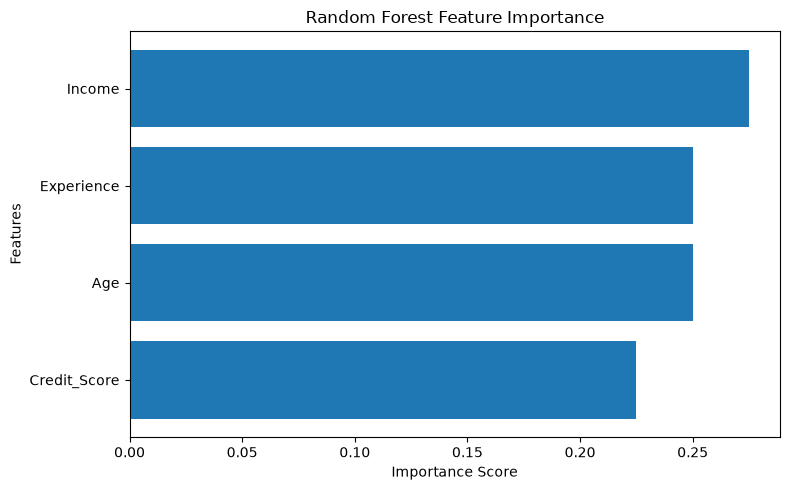

In [13]:
import matplotlib.pyplot as plt

rf_importance_sorted = rf_importance.sort_values(
    by="Importance"
)

plt.figure(figsize=(8, 5))

plt.barh(
    rf_importance_sorted["Feature"],
    rf_importance_sorted["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [14]:
feature_importance_summary = pd.DataFrame({
    "Topic": [
        "Feature Importance",
        "Model-Based Importance",
        "Decision Tree Importance",
        "Random Forest Importance",
        "Permutation Importance",
        "Importance vs Selection",
        "Interpreting Importance",
        "Limitations"
    ],
    "Purpose": [
        "Understand feature contributions",
        "Rank features using trained models",
        "Measure decision tree split importance",
        "Measure importance across multiple trees",
        "Measure performance change after shuffling",
        "Understand ranking versus selection",
        "Interpret feature rankings",
        "Understand potential biases and weaknesses"
    ]
})

display(feature_importance_summary)

,Topic,Purpose
0,Feature Importance,Understand feature contributions
1,Model-Based Importance,Rank features using trained models
2,Decision Tree Importance,Measure decision tree split importance
3,Random Forest Importance,Measure importance across multiple trees
4,Permutation Importance,Measure performance change after shuffling
5,Importance vs Selection,Understand ranking versus selection
6,Interpreting Importance,Interpret feature rankings
7,Limitations,Understand potential biases and weaknesses
